# Recovering a session's dipole fit

`2_intervention.py`'s `run_calibration()` ends by saving three files: `proc_info.npy`, the
calibration bundle, and `dipole_fitting_info.npy`. Those saves were added at different times, so
the early pilot sessions are missing some of them — and `dipole_fitting_info.npy` is the one that
matters most, because it is what fixes **where** in the brain, **which orientation**, and **which
time samples** every single-trial TEP amplitude is computed from. Without it, section 3 of
`PRIME_online_performance.ipynb` has nothing to read, and no trial from that session can be
re-fit on the dipole the online run actually used.

This notebook rebuilds that file for the sessions that are missing it, by replaying their
calibration trials through the session's *own saved* calibration state and calling the *same*
`DipoleFitter.calibrate()` the online decider called.

It is a **recovery / verification** notebook. The central question is not "what dipole comes out"
but "is the dipole that comes out the one that ran online", so the flow is: establish what can and
cannot be reconstructed (sections 2-3), build the replay (section 4), prove it reproduces a known
answer on the one session that still has its real file (section 5), and only then report the
recovered fits (section 6) with a check on how fragile they are (section 7).

Output format in sections 5-6 deliberately matches section 3 of `PRIME_online_performance.ipynb`,
so a recovered fit and a real one read identically.

## 1 · Setup

`LOOP_ROOT` is resolved the same way `PRIME_online_performance.ipynb` resolves it: the `LOOP_ROOT`
environment variable if set, else the lab Windows path `D:\Linus\Loop`, else `~/Desktop/Loop`, else
the first parent of the working directory holding both `BIDS/` and `prime/`.

Everything below uses the real online classes out of `prime/decider/prime_core` — `Preprocessor`,
`DipoleFitter`, and the `prime_config` accessors that read `configs/prime.yaml`. Nothing here
re-implements any part of the pipeline; the point of the exercise is defeated if it does.

In [1]:
from __future__ import annotations

import os, sys, csv, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (10, 3.4),
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError(
        "Could not locate the Loop root (a folder containing both 'BIDS' and 'prime'). "
        "Set the LOOP_ROOT environment variable."
    )


LOOP_ROOT = _find_loop_root()
sys.path.insert(0, str(LOOP_ROOT / "prime" / "decider"))

from prime_core.preprocessing.preprocessor import Preprocessor
from prime_core.preprocessing.dipole_fitter import DipoleFitter
from prime_core.prime_config import (
    get_raw_sfreq, get_qc_time_range, get_post_initial_time_range,
    get_ica_time_range, get_dipole_time_range, get_processed_sfreq, epoch_n_times,
)

FORWARD_PATH = LOOP_ROOT / "prime" / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
if not FORWARD_PATH.is_file():
    raise FileNotFoundError(
        f"Forward solution not found at {FORWARD_PATH}. prime/offline_data syncs separately from "
        f"the rest of the Loop tree; it must be present for any dipole fitting."
    )

RAW_SFREQ = get_raw_sfreq()
QC_TMIN, QC_TMAX = get_qc_time_range()
ICA_TMIN, ICA_TMAX = get_ica_time_range()
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()
DIPOLE_TMIN, DIPOLE_TMAX = get_dipole_time_range()
PROCESSED_SFREQ = get_processed_sfreq()

print(f"Loop root     : {LOOP_ROOT}")
print(f"forward model : {FORWARD_PATH.name}")
print(f"numpy {np.__version__}  pandas {pd.__version__}  mne {mne.__version__}")

Loop root     : D:\Linus\Loop
forward model : fsaverage-fwd.fif
numpy 2.3.2  pandas 2.3.1  mne 1.10.0


## 2 · What each session actually saved

The sessions do not share a folder layout or a file set. Pilot001's decider results were never
moved into the BIDS tree — they sit under `Import/Loop_Pilot_001/prime` — while Pilot002 onwards
live at `BIDS/sub-<subject>/<session>/<run>/prime`. Add a session by adding one row to `SESSIONS`.

Two file names matter and one of them is spelled two ways: the online code wrote
`calibration_bunble.npy` in the revision that ran these pilots (the typo is in
`2_intervention.py`, next to the comment `# CHANGE Linus - added step to save calibration bundle`),
and correctly as `calibration_bundle.npy` in later revisions. Both are accepted below.

`calibration_summary.csv` holds `num_calibration_trials` — the number of trials calibration
actually used after its three rejection stages. It exists for every session, including ones with no
bundle, and it is the only surviving record of that count. Section 5 leans on it heavily: it is the
one number that can confirm the replay reconstructed the right set of trials.

In [2]:
# ---------------------------------------------------------------- the sessions this notebook knows
SESSIONS = {
    "Pilot001": LOOP_ROOT / "Import" / "Loop_Pilot_001" / "prime",
    "Pilot002": LOOP_ROOT / "BIDS" / "sub-Pilot002" / "ses-prime" / "102" / "prime",
    "pilot003": LOOP_ROOT / "BIDS" / "sub-pilot003" / "ses-prime" / "103" / "prime",
    "pilot004": LOOP_ROOT / "BIDS" / "sub-pilot004" / "ses-prime" / "104" / "prime",
}

BUNDLE_NAMES = ("calibration_bunble.npy", "calibration_bundle.npy")


def find_bundle(session_dir: Path) -> Path | None:
    for name in BUNDLE_NAMES:
        if (session_dir / name).is_file():
            return session_dir / name
    return None


def n_calibration_trials(session_dir: Path) -> int:
    return len(sorted(session_dir.glob("calibration_*_pre_raw.npy")))


def online_trial_count(session_dir: Path) -> int | None:
    path = session_dir / "calibration_summary.csv"
    if not path.is_file():
        return None
    with open(path, newline="") as f:
        row = next(csv.DictReader(f), None)
    return int(row["num_calibration_trials"]) if row else None


inventory = pd.DataFrame([
    {
        "session": name,
        "folder exists": d.is_dir(),
        "bundle": (find_bundle(d).name if find_bundle(d) else "MISSING") if d.is_dir() else "-",
        "dipole_fitting_info.npy": (d / "dipole_fitting_info.npy").is_file() if d.is_dir() else False,
        "proc_info.npy": (d / "proc_info.npy").is_file() if d.is_dir() else False,
        "calibration trials on disk": n_calibration_trials(d) if d.is_dir() else 0,
        "trials used online": online_trial_count(d) if d.is_dir() else None,
    }
    for name, d in SESSIONS.items()
]).set_index("session")
inventory["trials used online"] = inventory["trials used online"].astype("Int64")

display(inventory)

REPLAYABLE = [n for n, d in SESSIONS.items() if d.is_dir() and find_bundle(d) is not None]
NEEDS_RECOVERY = [n for n in REPLAYABLE if not (SESSIONS[n] / "dipole_fitting_info.npy").is_file()]
HAS_GROUND_TRUTH = [n for n in REPLAYABLE if (SESSIONS[n] / "dipole_fitting_info.npy").is_file()]

print(f"replayable (a bundle exists)      : {', '.join(REPLAYABLE) or 'none'}")
print(f"still has its real online fit     : {', '.join(HAS_GROUND_TRUTH) or 'none'}   <- used to validate, section 5")
print(f"missing it, to be recovered here  : {', '.join(NEEDS_RECOVERY) or 'none'}   <- section 6")
print(f"not replayable at all             : "
      f"{', '.join(n for n in SESSIONS if n not in REPLAYABLE) or 'none'}   <- see section 3")

,folder exists,bundle,dipole_fitting_info.npy,proc_info.npy,calibration trials on disk,trials used online
session,,,,,,
Pilot001,True,MISSING,False,False,125,117
Pilot002,True,calibration_bunble.npy,True,True,125,112
pilot003,True,calibration_bunble.npy,True,True,125,108
pilot004,True,calibration_bunble.npy,True,True,125,113


replayable (a bundle exists)      : Pilot002, pilot003, pilot004
still has its real online fit     : Pilot002, pilot003, pilot004   <- used to validate, section 5
missing it, to be recovered here  : none   <- section 6
not replayable at all             : Pilot001   <- see section 3


## 3 · Why calibration cannot simply be re-run

The obvious approach — re-run `Preprocessor.calibrate()` on the saved calibration trials and let it
produce the dipole buffers again — does not work for any session, and the reason is a gap in what
was written to disk rather than anything about the algorithm.

`preprocess_calibration()` builds three epoch sets per trial: a QC window, an **ICA window**, and a
post-stimulus window. The ICA window is `[ica_tmin, ica_tmax]`, over a second of pre-stimulus data.
But the decider only ever saved two buffers per trial — `<stem>_pre_raw.npy` covering the QC window
and `<stem>_post_raw.npy` covering the initial post window. The ICA window was never saved, so the
ICA cannot be re-fit, and without the ICA there is no ocular rejection, no `ica.apply()`, and hence
no SOUND or SSP-SIR either.

The cell below prints the four windows and how much of each the saved buffers cover.

That gap is also exactly why **Pilot001 is unrecoverable**: it has no bundle (it ran before the
bundle-saving line existed) *and* the data needed to re-derive one is gone. The only remaining route
for it would be re-deriving a fresh calibration from its continuous `task-calibration` EEGLAB
recording, which would give a legitimate offline dipole fit but **not** the one that ran online — a
re-fit ICA yields different components, hence different ocular rejections, a different surviving
trial set, and a different evoked response.

For every session that *does* have a bundle, none of this matters: the bundle already contains
everything `preprocess_calibration()` produced — bad channels, the fitted ICA, the SOUND filter, the
SSP-SIR matrices, `good_trial_stats_qc` / `good_trial_stats_post`, `ocular_threshold_post`. The
replay restores those rather than recomputing them.

In [3]:
windows = pd.DataFrame([
    {"window": "ICA", "tmin_ms": ICA_TMIN * 1000, "tmax_ms": ICA_TMAX * 1000,
     "saved per trial?": "NO -- never written to disk"},
    {"window": "pre / QC", "tmin_ms": QC_TMIN * 1000, "tmax_ms": QC_TMAX * 1000,
     "saved per trial?": "yes, <stem>_pre_raw.npy"},
    {"window": "post (initial)", "tmin_ms": POST_I_TMIN * 1000, "tmax_ms": POST_I_TMAX * 1000,
     "saved per trial?": "yes, <stem>_post_raw.npy"},
    {"window": "dipole", "tmin_ms": DIPOLE_TMIN * 1000, "tmax_ms": DIPOLE_TMAX * 1000,
     "saved per trial?": "cropped out of the post window"},
])
windows["duration_ms"] = (windows.tmax_ms - windows.tmin_ms).round(1)
windows["n_samples"] = [epoch_n_times(r.tmin_ms / 1000, r.tmax_ms / 1000, PROCESSED_SFREQ)
                        for r in windows.itertuples()]
display(windows[["window", "tmin_ms", "tmax_ms", "duration_ms", "n_samples", "saved per trial?"]])

ica_ms = (ICA_TMAX - ICA_TMIN) * 1000
pre_ms = (QC_TMAX - QC_TMIN) * 1000
print(f"the ICA needs {ica_ms:.0f} ms of pre-stimulus data; the saved pre-buffer is {pre_ms:.0f} ms "
      f"({100 * pre_ms / ica_ms:.0f}% of it),")
print(f"and it starts at {QC_TMIN * 1000:.0f} ms, {abs(ICA_TMIN - QC_TMIN) * 1000:.0f} ms after the "
      f"ICA window opens -- so preprocess_calibration() cannot be re-run for any session.")

# What the bundle carries instead, for one session that has one.
_example_name = REPLAYABLE[0] if REPLAYABLE else None
if _example_name is not None:
    _example = SESSIONS[_example_name]
    _bundle = np.load(find_bundle(_example), allow_pickle=True).item()
    print(f"\ncontents of {find_bundle(_example).name} ({_example_name}), "
          f"i.e. what does not need recomputing:")
    for k in sorted(_bundle):
        v = _bundle[k]
        shape = getattr(v, "shape", None)
        desc = f"array{tuple(shape)}" if shape is not None else type(v).__name__
        print(f"  {k:32s} {desc}")

,window,tmin_ms,tmax_ms,duration_ms,n_samples,saved per trial?
0,ICA,-1100.0,-5.0,1095.0,1096,NO -- never written to disk
1,pre / QC,-210.0,-10.0,200.0,201,"yes, <stem>_pre_raw.npy"
2,post (initial),-30.0,100.0,130.0,131,"yes, <stem>_post_raw.npy"
3,dipole,38.0,50.0,12.0,13,cropped out of the post window


the ICA needs 1095 ms of pre-stimulus data; the saved pre-buffer is 200 ms (18% of it),
and it starts at -210 ms, 890 ms after the ICA window opens -- so preprocess_calibration() cannot be re-run for any session.

contents of calibration_bunble.npy (Pilot002), i.e. what does not need recomputing:
  bad_channels                     list
  channel_interpolation_info       dict
  good_trial_stats_post            dict
  good_trial_stats_qc              dict
  ica                              ICA
  ocular_threshold_post            dict
  qc_filter                        list
  sound_filter                     array(60, 60)
  sspsir_filter_kernel             array(60, 100)
  sspsir_sir_projmat_orig          array(60, 60)
  sspsir_sir_projmat_suppr         array(60, 60)
  sspsir_suppression_matrix_P      array(60, 60)


## 4 · The replay

With the bundle restored into a `Preprocessor`, each calibration trial is pushed through exactly the
two calls the online decider made on every *later* trial:

```python
model_buf = preprocessor.preprocess_pre(pre_raw, pre_ts, from_pulse=True)
post      = preprocessor.preprocess_post(post_raw, post_ts)
```

`preprocess_post()` returns the trial already cropped to the dipole window, which is precisely the
per-trial epoch calibration handed to `DipoleFitter.calibrate()`. Stacking the survivors therefore
rebuilds that function's input, and it can then be called unmodified.

**The one thing that is an approximation is which trials survive.** Online, calibration dropped
trials in three *group-level* stages (ocular ICA → pre-stimulus QC MAD → post-stimulus MAD) inside
`preprocess_calibration()`. Here each trial is gated individually, by the same checks against the
same stored thresholds: `preprocess_pre()` applies the QC MAD gate, `preprocess_post()` applies
ocular → global MAD → local MAD and stops at the first failure. Requiring **both** to pass is the
per-trial equivalent of surviving all three stages.

That equivalence is an assumption, not a theorem — which is what section 5 is for. `gate="post"`
keeps the alternative (post-stimulus processing only) available for the comparison in section 7.

In [4]:
def replay_calibration_trials(session_dir: Path, verbose: bool = True) -> dict:
    """Push every calibration trial through the session's own saved preprocessing."""
    bundle_path = find_bundle(session_dir)
    if bundle_path is None:
        raise FileNotFoundError(f"no calibration bundle in {session_dir}")

    bundle = np.load(bundle_path, allow_pickle=True).item()
    preprocessor = Preprocessor.from_bundle(bundle, FORWARD_PATH)

    n_trials = n_calibration_trials(session_dir)
    if n_trials == 0:
        raise FileNotFoundError(f"no calibration_*_pre_raw.npy files in {session_dir}")

    dipole_epochs, pre_ok, post_ok = [], [], []
    reject_reasons: dict[str, int] = {}

    for trial in range(n_trials):
        stem = f"calibration_{trial:04d}"
        pre_raw = np.load(session_dir / f"{stem}_pre_raw.npy")
        post_raw = np.load(session_dir / f"{stem}_post_raw.npy")
        pre_ts = QC_TMIN + np.arange(pre_raw.shape[0]) / RAW_SFREQ
        post_ts = POST_I_TMIN + np.arange(post_raw.shape[0]) / RAW_SFREQ

        model_buf = preprocessor.preprocess_pre(pre_raw, pre_ts, from_pulse=True)
        post = preprocessor.preprocess_post(post_raw, post_ts)

        pre_ok.append(model_buf is not None)
        post_ok.append(post is not None)
        dipole_epochs.append(post)
        if post is None:
            reason = preprocessor.last_post_reject_reason
            reject_reasons[reason] = reject_reasons.get(reason, 0) + 1

    out = {
        "session_dir": session_dir, "bundle": bundle_path.name, "n_trials": n_trials,
        "dipole_epochs": dipole_epochs, "pre_ok": pre_ok, "post_ok": post_ok,
        "reject_reasons": reject_reasons, "n_online": online_trial_count(session_dir),
    }
    if verbose:
        print(f"  {n_trials} calibration trials replayed: {sum(pre_ok)} passed pre-stim QC, "
              f"{sum(post_ok)} passed post-stim processing")
        if reject_reasons:
            print(f"  post-stim rejections: "
                  f"{', '.join(f'{k}={v}' for k, v in sorted(reject_reasons.items()))}")
    return out


def survivor_mask(replay: dict, gate: str = "both") -> list[bool]:
    """'both' = passed the pre-stim QC gate and post-stim processing; 'post' = post only."""
    if gate == "both":
        return [p and q for p, q in zip(replay["pre_ok"], replay["post_ok"])]
    if gate == "post":
        return list(replay["post_ok"])
    raise ValueError(f"gate must be 'both' or 'post', got {gate!r}")


def fit_from_survivors(replay: dict, gate: str = "both") -> tuple[dict, np.ndarray]:
    """Run the real DipoleFitter.calibrate() over the kept trials.

    Same class and same call the online decider used; only the stack of epochs handed to it is
    rebuilt here.
    """
    keep = survivor_mask(replay, gate)
    epochs = np.stack([e for e, k in zip(replay["dipole_epochs"], keep) if k and e is not None])
    fitter = DipoleFitter(FORWARD_PATH)
    amplitudes = fitter.calibrate(epochs)
    return dict(fitter.fitting_info), amplitudes


def print_fitting_info(info: dict) -> None:
    """Same wording and format as PRIME_online_performance.ipynb section 3."""
    pos_idx = info["position_index"]
    orientation = np.asarray(info["orientation"])
    idx_start, idx_end = info["index_range"]

    dipole_epoch_tmin_ms = DIPOLE_TMIN * 1000
    dipole_epoch_tmax_ms = DIPOLE_TMAX * 1000
    dt_ms = 1000.0 / PROCESSED_SFREQ
    # idx_end is an exclusive slice bound; the last *included* sample is idx_end - 1.
    window_tmin_ms = dipole_epoch_tmin_ms + idx_start * dt_ms
    window_tmax_ms = dipole_epoch_tmin_ms + (idx_end - 1) * dt_ms
    n_epoch_samples = epoch_n_times(DIPOLE_TMIN, DIPOLE_TMAX, PROCESSED_SFREQ)

    print(f"fsaverage source-space vertex index : {pos_idx}  (of 20484 ico-5 candidate positions)")
    print(f"dipole orientation (unit vector, x/y/z): {np.round(orientation, 4)}  "
          f"(norm = {np.linalg.norm(orientation):.4f})")
    print(f"optimal fitting window, as sample indices : [{idx_start}, {idx_end})  "
          f"= {idx_end - idx_start} of the {n_epoch_samples} epoch samples")
    print(f"optimal fitting window, as a time range    : {window_tmin_ms:.0f}-{window_tmax_ms:.0f} ms  "
          f"(within the {dipole_epoch_tmin_ms:.0f}-{dipole_epoch_tmax_ms:.0f} ms dipole epoch)")


def orientation_angle_deg(a, b) -> float:
    """Angle between two dipole orientations, sign-insensitive (a dipole axis has no arrow)."""
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    return float(np.degrees(np.arccos(np.clip(abs(np.dot(a, b)), -1.0, 1.0))))

## 5 · Validation — does the replay reproduce a known fit?

Every session with a bundle is replayed here (once; the result is reused for the rest of the
notebook, since this is the slow step). Two things are then checked against ground truth:

1. **The survivor count**, for every session, against `calibration_summary.csv`'s
   `num_calibration_trials`. This is available even for sessions whose dipole file is gone, and it
   directly tests the "both gates pass ≡ survived all three calibration stages" assumption from
   section 4.
2. **The fit itself**, for whichever session still has a real `dipole_fitting_info.npy`. If the
   replayed `position_index`, `index_range` and `orientation` come back identical to the file the
   online run wrote, the method is a reproduction rather than an approximation.

In [5]:
REPLAYS = {}
for name in REPLAYABLE:
    print(f"{name}  ({SESSIONS[name]})")
    REPLAYS[name] = replay_calibration_trials(SESSIONS[name])
    keep = survivor_mask(REPLAYS[name], "both")
    REPLAYS[name]["info"], REPLAYS[name]["amplitudes"] = fit_from_survivors(REPLAYS[name], "both")
    REPLAYS[name]["n_keep"] = sum(keep)
    print()

counts = pd.DataFrame([
    {
        "session": name,
        "delivered": r["n_trials"],
        "kept by replay": r["n_keep"],
        "used online": r["n_online"],
        "agrees": "yes" if r["n_keep"] == r["n_online"] else f"NO ({r['n_keep'] - r['n_online']:+d})",
    }
    for name, r in REPLAYS.items()
]).set_index("session")
display(counts)

Pilot002  (D:\Linus\Loop\BIDS\sub-Pilot002\ses-prime\102\prime)
  125 calibration trials replayed: 124 passed pre-stim QC, 113 passed post-stim processing
  post-stim rejections: local_mad=2, ocular=10

pilot003  (D:\Linus\Loop\BIDS\sub-pilot003\ses-prime\103\prime)
  125 calibration trials replayed: 120 passed pre-stim QC, 110 passed post-stim processing
  post-stim rejections: global_mad=1, local_mad=6, ocular=8

pilot004  (D:\Linus\Loop\BIDS\sub-pilot004\ses-prime\104\prime)
  125 calibration trials replayed: 122 passed pre-stim QC, 116 passed post-stim processing
  post-stim rejections: local_mad=1, ocular=8



,delivered,kept by replay,used online,agrees
session,,,,
Pilot002,125,112,112,yes
pilot003,125,108,108,yes
pilot004,125,113,113,yes


In [6]:
# ---------------------------------------------------------------- against the real saved fit
for name in HAS_GROUND_TRUTH:
    saved = np.load(SESSIONS[name] / "dipole_fitting_info.npy", allow_pickle=True).item()
    info = REPLAYS[name]["info"]
    angle = orientation_angle_deg(info["orientation"], saved["orientation"])
    same = (int(info["position_index"]) == int(saved["position_index"])
            and tuple(info["index_range"]) == tuple(saved["index_range"])
            and angle < 1.0)

    print(f"{name}: replay vs the real dipole_fitting_info.npy written by the online run")
    print(f"  position_index : replay {info['position_index']:<6} online {saved['position_index']:<6} "
          f"-> {'MATCH' if int(info['position_index']) == int(saved['position_index']) else 'DIFFERENT'}")
    print(f"  index_range    : replay {str(tuple(info['index_range'])):<6} "
          f"online {str(tuple(saved['index_range'])):<6} "
          f"-> {'MATCH' if tuple(info['index_range']) == tuple(saved['index_range']) else 'DIFFERENT'}")
    print(f"  orientation    : {angle:.3f} deg apart -> {'MATCH' if angle < 1.0 else 'DIFFERENT'}")
    print(f"  => {'the replay reproduces the online fit exactly' if same else 'THE REPLAY DOES NOT REPRODUCE THE ONLINE FIT'}")
    print()

if not HAS_GROUND_TRUTH:
    print("No session in SESSIONS still has a real dipole_fitting_info.npy, so the replay cannot be "
          "validated against ground truth here -- treat section 6's output as unverified.")

Pilot002: replay vs the real dipole_fitting_info.npy written by the online run
  position_index : replay 7524   online 7524   -> MATCH
  index_range    : replay (2, 8) online (2, 8) -> MATCH
  orientation    : 0.000 deg apart -> MATCH
  => the replay reproduces the online fit exactly

pilot003: replay vs the real dipole_fitting_info.npy written by the online run
  position_index : replay 3998   online 3998   -> MATCH
  index_range    : replay (3, 9) online (3, 9) -> MATCH
  orientation    : 0.000 deg apart -> MATCH
  => the replay reproduces the online fit exactly

pilot004: replay vs the real dipole_fitting_info.npy written by the online run
  position_index : replay 7558   online 7558   -> MATCH
  index_range    : replay (6, 12) online (6, 12) -> MATCH
  orientation    : 0.000 deg apart -> MATCH
  => the replay reproduces the online fit exactly



## 6 · The recovered fits

Same format as section 3 of `PRIME_online_performance.ipynb`. The amplitudes printed underneath are
what `DipoleFitter.calibrate()` returned for the calibration trials themselves — free orientation,
no normalisation — i.e. the same unnormalised scale chapter 2 of that notebook uses, and the values
`TEPNormalizer` was then calibrated on.

In [7]:
for name in NEEDS_RECOVERY:
    r = REPLAYS[name]
    print(f"{'=' * 78}\n{name}   (recovered from {r['n_keep']} calibration trials)\n{'=' * 78}")
    print_fitting_info(r["info"])
    a = r["amplitudes"]
    print(f"\ncalibration dipole amplitudes (free orientation, n={len(a)}): "
          f"median={np.median(a):.4f}  mean={np.mean(a):.4f}  sd={np.std(a):.4f}")
    print()

# Side by side with the sessions that already had a fit, for scale comparison.
summary = pd.DataFrame([
    {
        "session": name,
        "source": "recovered here" if name in NEEDS_RECOVERY else "real online file",
        "vertex": r["info"]["position_index"],
        "index_range": str(tuple(r["info"]["index_range"])),
        "window_ms": f"{DIPOLE_TMIN * 1000 + r['info']['index_range'][0]:.0f}-"
                     f"{DIPOLE_TMIN * 1000 + r['info']['index_range'][1] - 1:.0f}",
        "n_trials": r["n_keep"],
        "amp_median": round(float(np.median(r["amplitudes"])), 4),
        "amp_sd": round(float(np.std(r["amplitudes"])), 4),
    }
    for name, r in REPLAYS.items()
]).set_index("session")
display(summary)

,source,vertex,index_range,window_ms,n_trials,amp_median,amp_sd
session,,,,,,,
Pilot002,real online file,7524,"(2, 8)",40-45,112,0.1248,0.0708
pilot003,real online file,3998,"(3, 9)",41-46,108,0.0592,0.0300
pilot004,real online file,7558,"(6, 12)",44-49,113,0.1091,0.0555


## 7 · How much does the surviving trial set matter?

Section 5's count check is only meaningful if the fit is actually sensitive to the trial set — if
any reasonable subset gave the same dipole, matching the online count would prove nothing.

The cell below refits each session on the `"post"` gate instead (post-stimulus processing only, so a
handful of trials with an unusable pre-stimulus window are let back in) and compares. A result that
moves is the good outcome here: it means section 5's exact agreement with
`calibration_summary.csv` is load-bearing evidence, not a coincidence that would have held either
way.

In [8]:
rows = []
for name, r in REPLAYS.items():
    n_alt = sum(survivor_mask(r, "post"))
    if n_alt == r["n_keep"]:
        rows.append({"session": name, "gate 'both'": r["n_keep"], "gate 'post'": n_alt,
                     "vertex (both)": r["info"]["position_index"], "vertex (post)": "-",
                     "orientation shift": "-", "verdict": "both gates keep the same trials"})
        continue
    alt_info, _ = fit_from_survivors(r, "post")
    angle = orientation_angle_deg(alt_info["orientation"], r["info"]["orientation"])
    unchanged = (int(alt_info["position_index"]) == int(r["info"]["position_index"])
                 and tuple(alt_info["index_range"]) == tuple(r["info"]["index_range"])
                 and angle < 1.0)
    rows.append({
        "session": name, "gate 'both'": r["n_keep"], "gate 'post'": n_alt,
        "vertex (both)": r["info"]["position_index"], "vertex (post)": alt_info["position_index"],
        "orientation shift": f"{angle:.2f} deg",
        "verdict": "unchanged" if unchanged else "moves",
    })

display(pd.DataFrame(rows).set_index("session"))
print("'moves' means a handful of trials in or out of the average relocates the winning vertex --")
print("so reproducing the online trial count exactly (section 5) is what makes the fit trustworthy.")

,gate 'both',gate 'post',vertex (both),vertex (post),orientation shift,verdict
session,,,,,,
Pilot002,112,113,7524,2111,4.65 deg,moves
pilot003,108,110,3998,3996,1.69 deg,moves
pilot004,113,116,7558,7559,1.63 deg,moves


'moves' means a handful of trials in or out of the average relocates the winning vertex --
so reproducing the online trial count exactly (section 5) is what makes the fit trustworthy.


## 8 · Dipole position and orientation

The same three-view figure as section 3 of `PRIME_online_performance.ipynb`: the grey cloud is every
fsaverage source position the fit considered (20484 ico-5 vertices, both hemispheres), the red dot
is the winning vertex and the arrow is the fitted orientation. Arrow direction is exact; its length
is scaled for visibility only, since orientation is a unit vector carrying no magnitude.

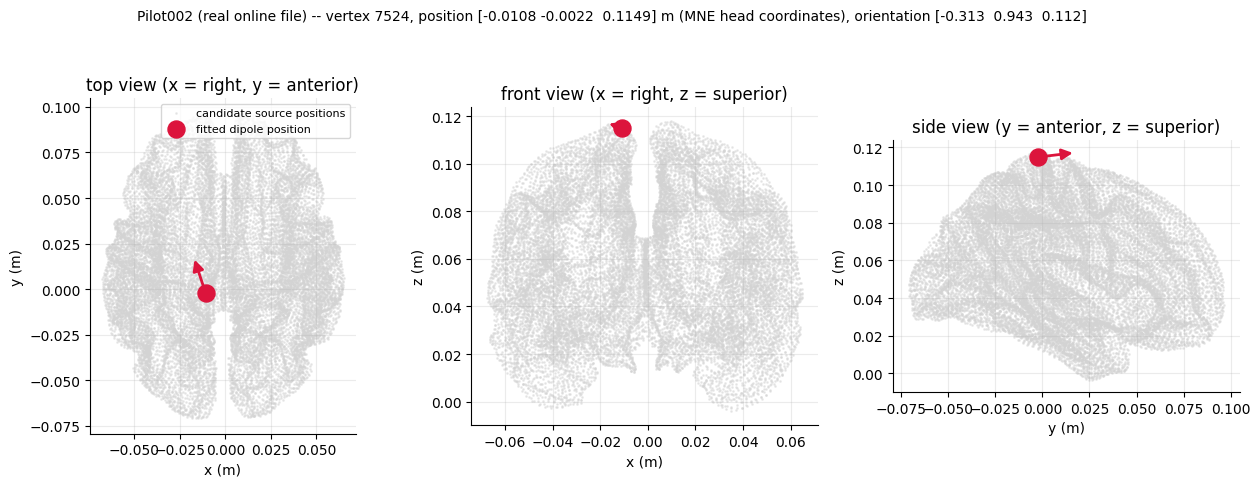

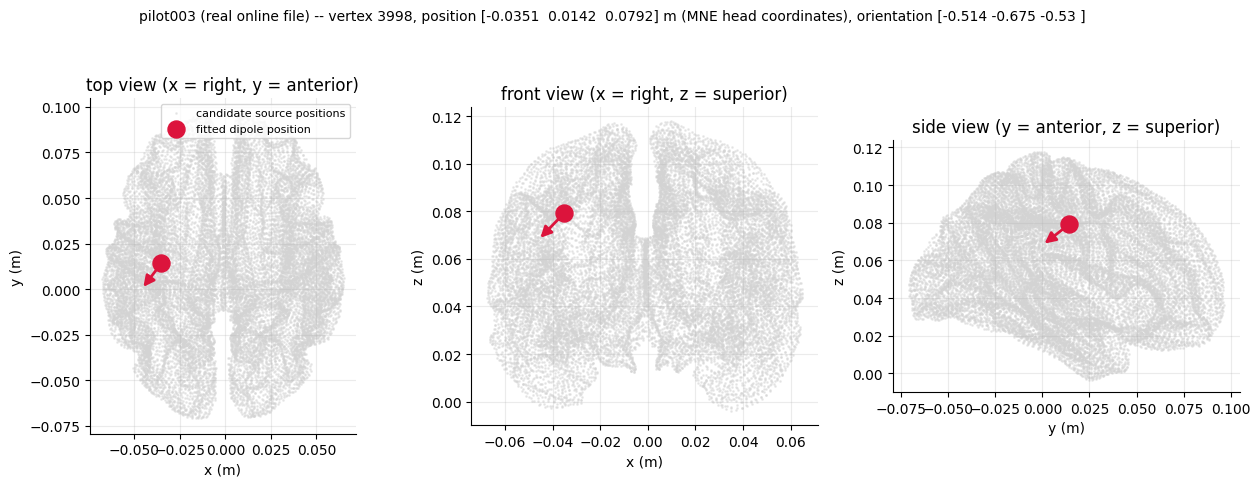

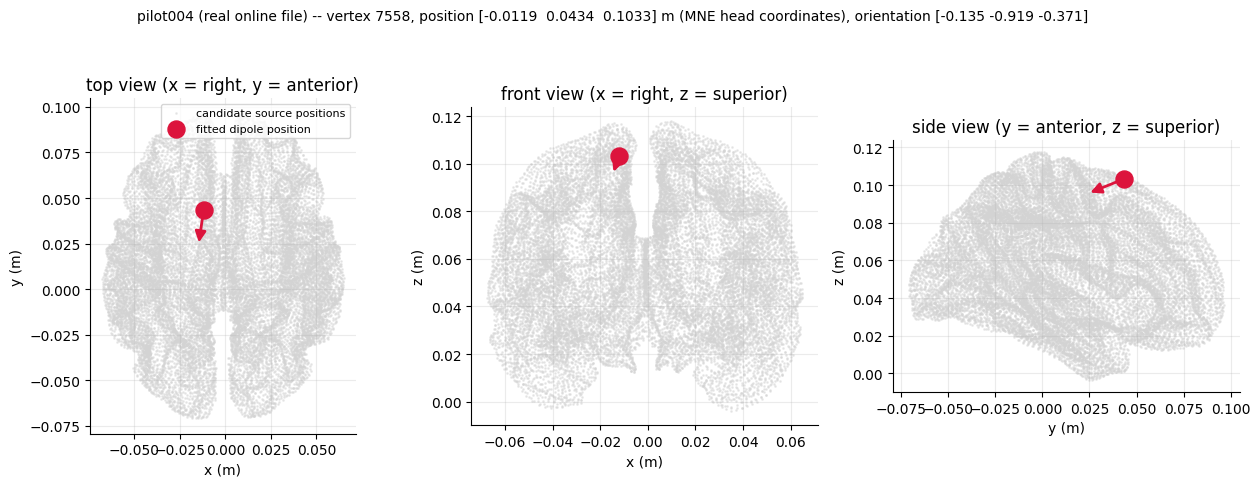

In [9]:
dipole_forward = mne.read_forward_solution(str(FORWARD_PATH), verbose=False)
source_rr = dipole_forward["source_rr"]           # (20484, 3) metres, MNE head coordinates
arrow_len = 0.15 * np.ptp(source_rr, axis=0).mean()

views = [("x", "y", "top view (x = right, y = anterior)"),
         ("x", "z", "front view (x = right, z = superior)"),
         ("y", "z", "side view (y = anterior, z = superior)")]
axis_idx = {"x": 0, "y": 1, "z": 2}

for name, r in REPLAYS.items():
    pos_idx = r["info"]["position_index"]
    orientation = np.asarray(r["info"]["orientation"])
    dipole_pos = source_rr[pos_idx]
    arrow_vec = orientation * arrow_len

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
    for ax, (h, v, title) in zip(axes, views):
        hi, vi = axis_idx[h], axis_idx[v]
        ax.scatter(source_rr[:, hi], source_rr[:, vi], s=1, color="lightgray", alpha=0.4,
                   label="candidate source positions" if ax is axes[0] else None)
        ax.scatter(dipole_pos[hi], dipole_pos[vi], s=150, color="crimson", zorder=5,
                   label="fitted dipole position" if ax is axes[0] else None)
        ax.annotate("", xy=(dipole_pos[hi] + arrow_vec[hi], dipole_pos[vi] + arrow_vec[vi]),
                    xytext=(dipole_pos[hi], dipole_pos[vi]),
                    arrowprops=dict(arrowstyle="-|>", color="crimson", lw=2, mutation_scale=16))
        ax.set_xlabel(f"{h} (m)")
        ax.set_ylabel(f"{v} (m)")
        ax.set_title(title)
        ax.set_aspect("equal")
    axes[0].legend(fontsize=8, loc="upper right")
    source = "recovered" if name in NEEDS_RECOVERY else "real online file"
    fig.suptitle(f"{name} ({source}) -- vertex {pos_idx}, position {np.round(dipole_pos, 4)} m "
                 f"(MNE head coordinates), orientation {np.round(orientation, 3)}",
                 y=1.05, fontsize=10)
    fig.tight_layout()
    plt.show()

## 9 · Writing `dipole_fitting_info.npy`

Off by default — flip `SAVE` to `True` to write the recovered fits into their session folders, which
is what makes `PRIME_online_performance.ipynb` (and anything else reading that file) work for those
sessions.

Two safeguards. A session that already has the file is skipped rather than overwritten, so a real
online fit can never be replaced by a replayed one. And the dict written carries three provenance
keys (`source`, `replay_n_trials`, `replay_gate`) alongside the three canonical ones — `DipoleFitter`
reads only `position_index`, `orientation` and `index_range` and ignores the rest, so the extras cost
nothing and stop a recovered file from being mistaken for an original later.

In [10]:
SAVE = False   # set True to write the recovered dipole_fitting_info.npy files

for name in NEEDS_RECOVERY:
    r = REPLAYS[name]
    target = SESSIONS[name] / "dipole_fitting_info.npy"
    if target.is_file():
        print(f"{name}: skipped, {target.name} already exists (that file is the real online one).")
        continue
    if not SAVE:
        print(f"{name}: would write {target}  (SAVE is False)")
        continue
    np.save(target, {
        "position_index": r["info"]["position_index"],
        "orientation": r["info"]["orientation"],
        "index_range": r["info"]["index_range"],
        "source": "replayed offline by scripts_analysis/replay_dipole_fit.ipynb",
        "replay_n_trials": int(r["n_keep"]),
        "replay_gate": "both",
    }, allow_pickle=True)
    print(f"{name}: wrote {target}")